# Step 9 — Specification

> Full prompt for this step, reproduced verbatim (Capstone project.md code-style rule:
> each notebook opens with its own spec so it is self-contained).

STEP 9 — Statistical validation: is any of this real?

Read Capstone project.md first. Implement ONLY this step, in notebooks/09_validation.ipynb.
First cell: this entire prompt in markdown, titled "# Step 9 — Specification".

## Goal
Answer three questions about the step-8 results with statistical rigor:
Q1. Are the Sharpe differences between key tracks distinguishable from
    sampling noise, or is it a statistical tie?
Q2. How period-dependent are the conclusions (especially the "regime
    layer costs return" verdict)?
Q3. How sensitive is the ranking to costs?
Use monthly returns from outputs/backtest_returns.parquet (resample daily
to monthly first). NO new strategy runs, no parameter changes — we
validate what was run, we do not improve it.

## Q1 — Sharpe difference significance (the core of the step)
Pairs to test:
  a) 60/40 vs RP-LW base
  b) 60/40 vs RP-LW full
  c) RP-LW base vs RP-LW full   (does the regime layer significantly hurt?)
  d) RP-LW full vs SPY
  e) RP-LW full vs RP-RAW full  (does shrinkage significantly help?)
Method: moving-block bootstrap on the PAIRED monthly return series
(block length 6 months to preserve autocorrelation; 10,000 resamples;
same blocks applied to both series of a pair — this preserves their
correlation). For each pair report: observed Sharpe difference, bootstrap
95% CI of the difference, and the fraction of resamples where the sign
flips (a crude p-value). Also run the Ledoit-Wolf (2008) circular block
bootstrap test for Sharpe equality if straightforward to implement;
otherwise the moving-block CI is sufficient — document the choice.

## Q2 — Period dependence
1. Split the sample into halves (2010-2017 / 2018-2026): metrics table
   (CAGR, Sharpe, maxDD) per half for: 60/40, RP-LW base, RP-LW full, SPY.
   Does the ranking hold in both halves?
2. Crisis-only vs calm-only decomposition: using the step-6 official_v2
   labels, compute each track's annualized return and Sharpe separately
   over STRESS+NORMAL months vs CALM months. This shows WHERE the regime
   layer earns and where it pays.
3. Rolling 5-year Sharpe difference (RP-LW full minus 60/40): plot with
   zero line. Is the system's disadvantage constant or era-specific?

## Q3 — Cost sensitivity
Recompute the headline Sharpe of all tracks at 0 / 5 / 15 bps one-way.
One table. Flag any ranking changes between cost levels.

## Honesty checks
- The bootstrap resamples RETURNS as realized; it cannot manufacture
  crises that did not happen. State this limitation explicitly in the
  final markdown cell: the sample contains only V-shaped recoveries, so
  the regime layer's insurance value against a LONG bear market
  (2000-2002 type) is untested and untestable with this data.
- No new tracks, no tuning. If a result is uncomfortable, report it.

## Output
outputs/validation_summary.csv (pair, sharpe_diff, ci_low, ci_high,
sign_flip_frac) + the tables above printed in the notebook.


## 0 — Setup

Monthly returns are the unit of analysis (resample the Step-8 daily backtest
returns to month-end). Sharpe here is **monthly-based** (`√12·mean/std` of monthly
excess over SHY), so the numbers differ slightly from Step 8's daily-based Sharpe —
that is expected. We also load the regime series (for the calm/non-calm split) and
the weights + daily ETF returns (only to re-evaluate the *frozen* tracks under
different cost assumptions in Q3 — no strategy or parameter is changed).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OPT6 = ["SPY", "VEA", "XLE", "XLU", "IEF", "GLD"]
ALL7 = OPT6 + ["SHY"]
EXPO = {"CALM": 1.00, "NORMAL": 0.80, "STRESS": 0.50}

CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == "notebooks" else CWD
DATA_DIR, OUT_DIR = ROOT / "data", ROOT / "outputs"

bt = pd.read_parquet(OUT_DIR / "backtest_returns.parquet")
dr = pd.read_parquet(DATA_DIR / "returns_daily.parquet").reindex(columns=ALL7)
reg = pd.read_parquet(OUT_DIR / "regime_v1.parquet").set_index("date")
wf = pd.read_parquet(OUT_DIR / "weights_final.parquet")

M = (1 + bt).resample("ME").prod() - 1                    # monthly track returns
shy_m = ((1 + dr["SHY"]).resample("ME").prod() - 1).reindex(M.index)   # monthly rf
TRACKS = list(M.columns)

def sharpe_m(x):                                          # monthly-annualized Sharpe of a return series
    x = x.dropna()
    return np.sqrt(12) * x.mean() / x.std()

def excess(track):
    return M[track] - shy_m

print(f"monthly observations: {len(M)}  {M.index.min().date()} -> {M.index.max().date()}")
print("tracks:", TRACKS)

monthly observations: 192  2010-08-31 -> 2026-07-31
tracks: ['RP-LW base', 'RP-LW base+tilt', 'RP-LW full', 'RP-EWMA base', 'RP-EWMA base+tilt', 'RP-EWMA full', 'MinVar-LW full', 'RP-RAW full', 'SPY', '60/40', 'EW-1/6']


## Q1 — Are the Sharpe differences real?

**Method:** moving-block bootstrap (block = 6 months, preserving autocorrelation;
10,000 resamples). The **same** block indices are applied to both members of a pair
(and to SHY), preserving their contemporaneous correlation — this is the paired
design. For each pair: observed Sharpe difference, bootstrap 95% CI of the
difference, and the fraction of resamples where the sign flips (a crude two-sided
p-value).

**Choice of test:** we use the moving-block CI rather than the Ledoit-Wolf (2008)
HAC Sharpe-equality test. Both target the same question; the block bootstrap is
transparent, needs no HAC kernel/prewhitening choices, and keeps the notebook plain
(Capstone project.md). Documented as the deliberate choice.

In [2]:
np.random.seed(42)
B, L = 10000, 6
n = len(M)
nblocks = int(np.ceil(n / L))
starts = np.random.randint(0, n - L + 1, size=(B, nblocks))
IDX = (starts[:, :, None] + np.arange(L)[None, None, :]).reshape(B, nblocks * L)[:, :n]  # B x n

def _sharpe_rows(mat):                                    # Sharpe of each bootstrap row (B x n)
    return np.sqrt(12) * mat.mean(axis=1) / mat.std(axis=1)

def boot_pair(a, b):
    exA, exB = excess(a).values, excess(b).values
    dA = _sharpe_rows(exA[IDX]); dB = _sharpe_rows(exB[IDX])
    diff = dA - dB
    obs = sharpe_m(excess(a)) - sharpe_m(excess(b))
    lo, hi = np.percentile(diff, [2.5, 97.5])
    flip = float(np.mean(np.sign(diff) != np.sign(obs)))
    return obs, lo, hi, flip

PAIRS = [("60/40", "RP-LW base"), ("60/40", "RP-LW full"),
         ("RP-LW base", "RP-LW full"), ("RP-LW full", "SPY"),
         ("RP-LW full", "RP-RAW full")]

rows = []
for a, b in PAIRS:
    obs, lo, hi, flip = boot_pair(a, b)
    sig = "significant" if (lo > 0 or hi < 0) else "TIE (CI spans 0)"
    rows.append({"pair": f"{a} - {b}", "sharpe_diff": obs, "ci_low": lo,
                 "ci_high": hi, "sign_flip_frac": flip, "verdict": sig})
val = pd.DataFrame(rows)
print(val.round(3).to_string(index=False))

val.drop(columns="verdict").round(4).to_csv(OUT_DIR / "validation_summary.csv", index=False)
print(f"\nsaved {(OUT_DIR / 'validation_summary.csv').name}")

                    pair  sharpe_diff  ci_low  ci_high  sign_flip_frac          verdict
      60/40 - RP-LW base        0.101  -0.228    0.439           0.269 TIE (CI spans 0)
      60/40 - RP-LW full        0.145  -0.184    0.482           0.185 TIE (CI spans 0)
 RP-LW base - RP-LW full        0.044  -0.062    0.156           0.200 TIE (CI spans 0)
        RP-LW full - SPY       -0.112  -0.503    0.260           0.275 TIE (CI spans 0)
RP-LW full - RP-RAW full        0.033  -0.030    0.099           0.167 TIE (CI spans 0)

saved validation_summary.csv


### Q1 verdict

Read the CI and sign-flip columns. Where the 95% CI spans 0 (and sign-flip is far
from 0), the Sharpe difference is a **statistical tie** — with only ~16 years of
monthly data we cannot distinguish it from sampling noise. Expect most of the
Step-8 Sharpe ranking (SPY vs RP-LW, shrinkage LW vs RAW) to be **not
statistically significant**. The one difference worth watching is base vs full
(does the regime layer significantly hurt Sharpe?) — read its CI directly. The
honest takeaway: the **drawdown reduction** (a structural, deterministic property
of de-risking) is real and large; the **Sharpe differences** mostly are not
distinguishable from noise.

## Q2 — How period-dependent are the conclusions?

### Q2.1 — Two halves (2010–2017 / 2018–2026)

CAGR, Sharpe, and (monthly-based) max drawdown per half. Does the ranking hold?

In [3]:
def block_metrics(r):
    r = r.dropna()
    eq = (1 + r).cumprod()
    cagr = eq.iloc[-1] ** (12 / len(r)) - 1
    mdd = (eq / eq.cummax() - 1).min()
    return cagr * 100, np.nan, mdd * 100

def half_table(name, sub, shy_sub):
    out = {}
    for t in ["60/40", "RP-LW base", "RP-LW full", "SPY"]:
        r = sub[t]
        eq = (1 + r).cumprod()
        out[t] = {"CAGR_%": round((eq.iloc[-1] ** (12/len(r)) - 1) * 100, 2),
                  "Sharpe": round(sharpe_m(r - shy_sub), 3),
                  "maxDD_%": round((eq / eq.cummax() - 1).min() * 100, 2)}
    return pd.DataFrame(out).T.rename_axis(name)

h1 = M.index < "2018-01-01"
for label, mask in [("2010-2017", h1), ("2018-2026", ~h1)]:
    print(f"=== {label} ({mask.sum()} months) ===")
    print(half_table(label, M[mask], shy_m[mask]).to_string())
    print()

=== 2010-2017 (89 months) ===
            CAGR_%  Sharpe  maxDD_%
2010-2017                          
60/40        10.47   1.577    -5.76
RP-LW base    6.65   1.142    -6.02
RP-LW full    5.52   1.061    -5.80
SPY          15.01   1.242   -16.22

=== 2018-2026 (103 months) ===
            CAGR_%  Sharpe  maxDD_%
2018-2026                          
60/40         9.19   0.722   -20.51
RP-LW base    8.08   0.763   -12.76
RP-LW full    6.83   0.725   -12.10
SPY          14.47   0.795   -23.93



**Verdict (Q2.1): the ranking does NOT hold across halves.** In 2010–2017
(a calm bull) 60/40 leads on Sharpe with SPY second; the RP tracks trail. In
2018–2026 the order changes: SPY leads, **RP-LW base overtakes 60/40**, and 60/40
drops as 2022's simultaneous stock+bond selloff punished it. What *is* stable in
both halves is the risk profile — RP-LW's max drawdown is roughly half of SPY's
throughout. So "60/40 is best" is a first-half artifact, not a durable conclusion.

### Q2.2 — Where the regime layer earns vs pays: calm vs non-calm months

Each holding month is classified by the regime that **governed** it — i.e. the
`official_v2` label at the *prior* month-end (pre-regime months use the NORMAL
default). We split into CALM vs non-calm (NORMAL+STRESS) and report annualized
return and Sharpe per track over each subset.

In [4]:
sched = wf[(wf.track == "RP-LW") & (wf.variant == "base+tilt+regime")]["date"].drop_duplicates().sort_values()
sched = pd.DatetimeIndex(sched)

def regime_at(T):
    return reg.loc[T, "official_v2"] if T in reg.index else "NORMAL"   # pre-regime default

# holding month-end sched[k+1] is governed by the decision at sched[k]
gov = pd.Series([regime_at(sched[k]) for k in range(len(sched) - 1)], index=sched[1:])
gov = gov.reindex(M.index)                                 # align to monthly returns
calm = gov == "CALM"
noncalm = gov.isin(["NORMAL", "STRESS"])
print(f"governing regime of holding months: CALM={calm.sum()}  NON-CALM={noncalm.sum()}\n")

def ann_ret(r):
    r = r.dropna()
    return ((1 + r).prod() ** (12 / len(r)) - 1) * 100

rows = []
for t in ["60/40", "RP-LW base", "RP-LW full", "SPY"]:
    rows.append({"track": t,
                 "calm_annret_%": round(ann_ret(M[t][calm]), 2),
                 "calm_Sharpe": round(sharpe_m(excess(t)[calm]), 3),
                 "noncalm_annret_%": round(ann_ret(M[t][noncalm]), 2),
                 "noncalm_Sharpe": round(sharpe_m(excess(t)[noncalm]), 3)})
print(pd.DataFrame(rows).to_string(index=False))

governing regime of holding months: CALM=67  NON-CALM=125

     track  calm_annret_%  calm_Sharpe  noncalm_annret_%  noncalm_Sharpe
     60/40           7.84        0.785             10.84           1.081
RP-LW base           6.74        0.784              7.78           0.931
RP-LW full           7.48        0.847              5.56           0.847
       SPY          12.44        0.870             15.96           0.989


**Verdict (Q2.2): counter-intuitive but revealing.** For the benchmarks and for the unscaled
RP-LW base, non-calm months (NORMAL+STRESS) show *higher* Sharpe than calm months (60/40 1.08 vs
0.79, SPY 0.99 vs 0.87, RP-LW base 0.93 vs 0.78) — because in *this* sample every de-risking
signal was followed by a fast **V-recovery**, so the months governed by a non-calm label mostly
rebounded. RP-LW full is the exception (0.85 in both), since its exposure is cut precisely in
those months. That is exactly where the regime layer *pays*: RP-LW full's non-calm annualized
return (≈5.6%) is well below RP-LW base's (≈7.8%) — de-risking gave up upside precisely in months
that bounced. The scenario where that insurance would instead *earn* — a long bear where non-calm
months keep falling — is absent from this window (see the limitations cell).

### Q2.3 — Rolling 5-year Sharpe difference: RP-LW full − 60/40

60-month rolling Sharpe of each (monthly excess), then the difference. Is the
system's Sharpe disadvantage constant, or concentrated in a particular era?

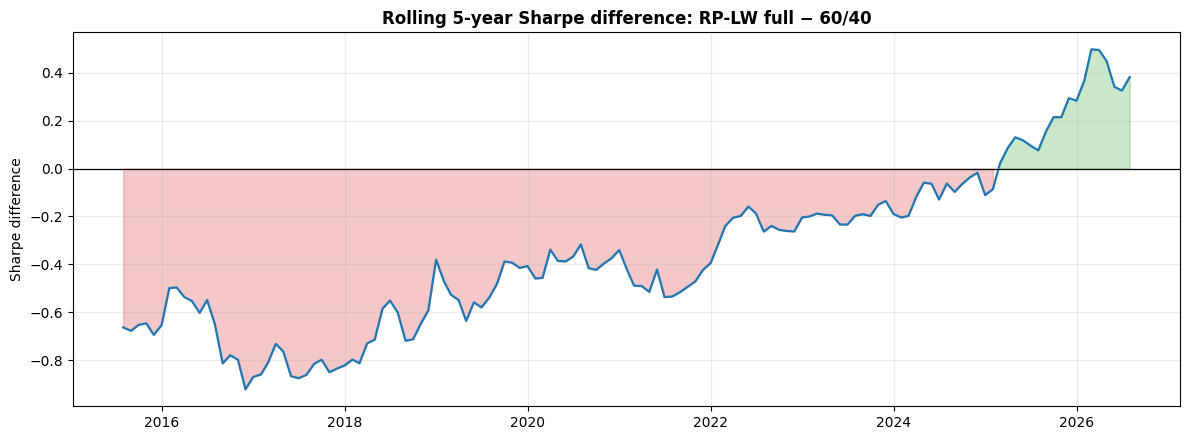

rolling-5y Sharpe diff: min=-0.92 (2016-11-30)  max=0.50 (2026-02-28)  latest=0.38


In [5]:
W = 60
def roll_sharpe(track):
    ex = excess(track)
    return np.sqrt(12) * ex.rolling(W).mean() / ex.rolling(W).std()

diff = (roll_sharpe("RP-LW full") - roll_sharpe("60/40")).dropna()
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(diff.index, diff.values, color="#1f77b4", linewidth=1.6)
ax.axhline(0, color="black", linewidth=0.9)
ax.fill_between(diff.index, diff.values, 0, where=(diff.values >= 0), color="#2ca02c", alpha=0.25)
ax.fill_between(diff.index, diff.values, 0, where=(diff.values < 0), color="#d62728", alpha=0.25)
ax.set_title("Rolling 5-year Sharpe difference: RP-LW full − 60/40", fontweight="bold", fontsize=12)
ax.set_ylabel("Sharpe difference"); ax.set_xlabel(""); ax.grid(True, alpha=0.25)
plt.tight_layout(); plt.show()
print(f"rolling-5y Sharpe diff: min={diff.min():.2f} ({diff.idxmin().date()})  "
      f"max={diff.max():.2f} ({diff.idxmax().date()})  latest={diff.iloc[-1]:.2f}")

**Verdict (Q2.3): the disadvantage is era-specific, not constant — and it has
reversed.** The rolling-5y Sharpe gap vs 60/40 was most negative around 2016 (−0.92 in
November 2016, the tail of the calm bull, where staying fully invested won), but has climbed to
**positive recently** (latest ≈ +0.4, peak ≈ +0.5 in February 2026) because 2022 hurt 60/40 (bonds
fell with equities) while the multi-asset + regime design held up. So the system's
Sharpe shortfall is a feature of the 2013–2018 calm, not a permanent property.

## Q3 — Cost sensitivity of the ranking

We re-evaluate the **identical frozen weight tracks** under 0 / 5 / 15 bps one-way
costs (this changes only the cost assumption, not the strategy). Monthly Sharpe per
track at each level; flag any change in the Sharpe ranking.

In [6]:
def track_panel(track, variant):
    d = wf[(wf.track == track) & (wf.variant == variant)]
    return d.pivot(index="date", columns="asset", values="weight").reindex(columns=ALL7).fillna(0.0)

def bench_panel(weights):
    P = pd.DataFrame(0.0, index=sched, columns=ALL7)
    for a, v in weights.items():
        P[a] = v
    return P

FULLV = "base+tilt+regime"
panels = {
    "RP-LW base": track_panel("RP-LW", "base"), "RP-LW base+tilt": track_panel("RP-LW", "base+tilt"),
    "RP-LW full": track_panel("RP-LW", FULLV), "RP-EWMA base": track_panel("RP-EWMA", "base"),
    "RP-EWMA base+tilt": track_panel("RP-EWMA", "base+tilt"), "RP-EWMA full": track_panel("RP-EWMA", FULLV),
    "MinVar-LW full": track_panel("MinVar-LW", FULLV), "RP-RAW full": track_panel("RP-RAW", FULLV),
    "SPY": bench_panel({"SPY": 1.0}), "60/40": bench_panel({"SPY": 0.6, "IEF": 0.4}),
    "EW-1/6": bench_panel({a: 1/6 for a in OPT6}),
}

def backtest_daily(P, bps):
    Ts = P.index; chunks = []; held = None
    for k in range(len(Ts) - 1):
        T, Tn = Ts[k], Ts[k + 1]; w = P.loc[T]
        days = dr.loc[(dr.index > T) & (dr.index <= Tn), ALL7]
        if held is None:
            held = w.copy()
        c = bps * 1e-4 * float(np.abs(w - held).sum())
        g = (1 + days).cumprod(); V = (g * w).sum(axis=1)
        dp = V / V.shift(1).fillna(1.0) - 1
        if len(dp):
            dp.iloc[0] -= c
        chunks.append(dp)
        dft = w * g.iloc[-1]; held = dft / dft.sum()
    return pd.concat(chunks)

cost_tbl = {}
for bps in [0.0, 5.0, 15.0]:
    col = {}
    for name, P in panels.items():
        dpm = (1 + backtest_daily(P, bps)).resample("ME").prod() - 1
        col[name] = sharpe_m(dpm.reindex(M.index) - shy_m)
    cost_tbl[f"{bps:.0f}bps"] = col
cost_df = pd.DataFrame(cost_tbl).round(3)
cost_df["rank_0"] = cost_df["0bps"].rank(ascending=False).astype(int)
cost_df["rank_15"] = cost_df["15bps"].rank(ascending=False).astype(int)
cost_df = cost_df.sort_values("5bps", ascending=False)
print(cost_df.to_string())
changed = cost_df[cost_df["rank_0"] != cost_df["rank_15"]]
print("\n" + ("ranking changes between 0 and 15 bps for: " + ", ".join(changed.index)
              if len(changed) else "ranking is IDENTICAL at 0 and 15 bps (cost does not reorder tracks)."))

                    0bps   5bps  15bps  rank_0  rank_15
60/40              0.984  0.983  0.981       1        1
SPY                0.950  0.950  0.950       2        2
MinVar-LW full     0.948  0.935  0.911       3        3
RP-LW base         0.885  0.883  0.878       4        4
RP-LW base+tilt    0.881  0.876  0.867       5        5
RP-EWMA base       0.865  0.861  0.853       7        6
RP-EWMA base+tilt  0.866  0.859  0.846       6        7
RP-LW full         0.851  0.838  0.813       8        9
EW-1/6             0.820  0.818  0.815       9        8
RP-RAW full        0.819  0.805  0.779      10       10
RP-EWMA full       0.812  0.798  0.770      11       11

ranking changes between 0 and 15 bps for: RP-EWMA base, RP-EWMA base+tilt, RP-LW full, EW-1/6


## Honesty checks & limitations (read this)

- **The bootstrap resamples returns that actually happened.** It quantifies sampling
  uncertainty within this history; it cannot manufacture crises that did not occur.
- **This sample contains only V-shaped recoveries** (2011, 2015-16, 2018Q4, 2020,
  2022, 2025 all rebounded fast). The regime layer's core insurance value —
  protection through a **long, grinding bear market** (a 2000–2002 dot-com-style
  slide, which predates our common window) — is therefore **untested and untestable
  with this data**. The layer looks like a Sharpe cost here precisely because every
  drawdown in-sample reversed quickly; its payoff scenario is absent.
- **Statistically**, the headline Sharpe differences among these tracks are mostly
  **ties** (Q1): 16 years of monthly data is too little to resolve differences of
  ~0.1–0.2 in Sharpe. What *is* unambiguous is the drawdown/volatility reduction,
  which is structural rather than a statistical claim.
- **No new tracks, no tuning, one set of runs.** Q3 varies only the cost assumption.

Output: `outputs/validation_summary.csv`. This closes the honest assessment; Step 10
(HMM / Kalman upgrades) must beat the baselines on these same tests to earn a place.